# Radiografía del delito en Los Ángeles (2020–2023)
**Certamen 2 — Entrega final, Bloques 1 a 7** · Taller de Visualización de la Información (UDD)
Juan Pablo Castillo · Martín Cáceres · Emilio Pacheco

**Dataset:** *Crimes in Los Angeles 2020–2023* (Kaggle, asaniczka) · Fuente: LAPD · Licencia CC0 · Acceso: 06-10-2026.
Antes de correr: subir `Crime_Data_from_2020_to_Present.csv` a `/content/` (panel de archivos de Colab) y esperar a que termine de cargar.

In [24]:
# Librerías clásicas (Clase 5)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use("ggplot")
# Filtrar warnings
import warnings
warnings.filterwarnings("ignore")

## Bloque 1 — Perfil general del dataset: ¿qué datos tengo?
*Feedback del Avance 2:* sin observaciones de contenido; se mantiene el bloque.

In [25]:
# Carga del dataset
ruta = "/content/Crime_Data_from_2020_to_Present.csv"
df = pd.read_csv(ruta)
df.shape  # (filas, columnas)

(852950, 27)

In [26]:
# Tipos de datos, nulos por columna y memoria
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 852950 entries, 0 to 852949
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   division_number      852950 non-null  int64  
 1   date_reported        852950 non-null  object 
 2   date_occurred        852950 non-null  object 
 3   area                 852950 non-null  int64  
 4   area_name            852950 non-null  object 
 5   reporting_district   852950 non-null  int64  
 6   part                 852950 non-null  int64  
 7   crime_code           852950 non-null  int64  
 8   crime_description    852950 non-null  object 
 9   modus_operandi       734639 non-null  object 
 10  victim_age           852950 non-null  int64  
 11  victim_sex           740344 non-null  object 
 12  victim_descent       740336 non-null  object 
 13  premise_code         852940 non-null  float64
 14  premise_description  852432 non-null  object 
 15  weapon_code      

In [27]:
# Muestra aleatoria de 5 registros
df.sample(5)

,division_number,date_reported,date_occurred,area,area_name,reporting_district,part,crime_code,crime_description,modus_operandi,...,status,status_description,crime_code_1,crime_code_2,crime_code_3,crime_code_4,location,cross_street,latitude,longitude
277102,211004847,2021-01-26,2021-01-25 20:30:00,10,West Valley,1004,1,330,BURGLARY FROM VEHICLE,1300 0358 0377 1822 0344 0321,...,IC,Invest Cont,330.0,NaN,NaN,NaN,7700 NESTLE AV,NaN,34.2105,-118.5307
222382,210405692,2021-02-16,2021-02-14 17:00:00,4,Hollenbeck,466,1,480,BIKE - STOLEN,0344,...,IC,Invest Cont,480.0,NaN,NaN,NaN,2500 MICHIGAN AV,NaN,34.0442,-118.2063
508439,220915981,2022-11-10,2022-11-08 15:30:00,9,Van Nuys,964,1,330,BURGLARY FROM VEHICLE,0344,...,IC,Invest Cont,330.0,NaN,NaN,NaN,13700 RIVERSIDE DR,NaN,34.1576,-118.4312
118161,201210297,2020-04-03,2020-04-03 22:30:00,12,77th Street,1204,2,740,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...",0329 1307,...,IC,Invest Cont,740.0,NaN,NaN,NaN,47TH ST,VERMONT,34.0006,-118.2915
602573,221413828,2022-01-10,2022-01-10 09:00:00,14,Pacific,1455,2,354,THEFT OF IDENTITY,0377,...,IC,Invest Cont,354.0,NaN,NaN,NaN,4200 KENYON AV,NaN,33.9944,-118.4287


### Diccionario de variables
Fuente de las descripciones: diccionario oficial del LAPD (data.lacity.org). Ejemplos tomados del dataset.

| Variable | Tipo original | Descripción | Unidad | Ejemplo |
|---|---|---|---|---|
| division_number | int64 | Número de denuncia (identificador único; DR_NO en el LAPD) | — | 10304468 |
| date_reported | object | Fecha en que se hizo la denuncia | fecha | 2020-01-08 |
| date_occurred | object | Fecha y hora en que ocurrió el delito | fecha y hora | 2020-01-08 22:30:00 |
| area | int64 | Código del área policial (21 áreas) | — | 3 |
| area_name | object | Nombre del área policial | — | Southwest |
| reporting_district | int64 | Subdistrito de reporte dentro del área | — | 377 |
| part | int64 | Gravedad según el FBI (1 = más grave, 2 = menos grave) | — | 2 |
| crime_code | int64 | Código del delito | — | 624 |
| crime_description | object | Descripción del delito | — | BATTERY - SIMPLE ASSAULT |
| modus_operandi | object | Códigos del modo de operar del delincuente | — | 0444 0913 |
| victim_age | int64 | Edad de la víctima | años | 36 |
| victim_sex | object | Sexo de la víctima (F, M, X) | — | F |
| victim_descent | object | Código de origen étnico de la víctima | — | B |
| premise_code | float64 | Código del tipo de lugar | — | 501.0 |
| premise_description | object | Tipo de lugar donde ocurrió | — | SINGLE FAMILY DWELLING |
| weapon_code | float64 | Código del arma usada | — | 400.0 |
| weapon_description | object | Arma usada | — | STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE) |
| status | object | Código del estado del caso | — | AO |
| status_description | object | Estado del caso | — | Adult Other |
| crime_code_1 a crime_code_4 | float64 | Códigos de delitos adicionales del mismo hecho | — | 624.0 |
| location | object | Dirección (redondeada a la centena de cuadra) | — | 1100 W 39TH PL |
| cross_street | object | Calle transversal | — | — |
| latitude | float64 | Latitud | grados | 34.0141 |
| longitude | float64 | Longitud | grados | -118.2978 |

### Corrección de tipos
- **Fechas** (texto → `datetime`): permiten extraer hora, día y mes y calcular retrasos.
- **Identificador** `division_number` (número → texto): no es una cantidad.
- **Códigos** (número → `category`): son etiquetas; promediarlos no tiene sentido.
- **Textos repetidos** (object → `category`): pocos valores que se repiten (21 áreas, 138 delitos); ocupan menos memoria.
- Se mantienen numéricas `victim_age`, `latitude` y `longitude`, que sí son cantidades.

In [28]:
# Fechas: texto -> datetime (Guía Netflix)
df["date_reported"] = pd.to_datetime(df["date_reported"])
df["date_occurred"] = pd.to_datetime(df["date_occurred"])

# Identificador: número -> texto (Control II)
df["division_number"] = df["division_number"].astype("str")

# Códigos: número -> category
df["area"] = df["area"].astype("category")
df["reporting_district"] = df["reporting_district"].astype("category")
df["part"] = df["part"].astype("category")
df["crime_code"] = df["crime_code"].astype("category")
df["premise_code"] = df["premise_code"].astype("category")
df["weapon_code"] = df["weapon_code"].astype("category")
df["crime_code_1"] = df["crime_code_1"].astype("category")
df["crime_code_2"] = df["crime_code_2"].astype("category")
df["crime_code_3"] = df["crime_code_3"].astype("category")
df["crime_code_4"] = df["crime_code_4"].astype("category")

# Textos repetidos: object -> category
df["status"] = df["status"].astype("category")
df["area_name"] = df["area_name"].astype("category")
df["crime_description"] = df["crime_description"].astype("category")
df["victim_sex"] = df["victim_sex"].astype("category")
df["victim_descent"] = df["victim_descent"].astype("category")
df["premise_description"] = df["premise_description"].astype("category")
df["weapon_description"] = df["weapon_description"].astype("category")
df["status_description"] = df["status_description"].astype("category")

In [29]:
# Verificación: nuevos tipos y memoria (de 175,7+ MB a 78,2+ MB)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 852950 entries, 0 to 852949
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   division_number      852950 non-null  object        
 1   date_reported        852950 non-null  datetime64[ns]
 2   date_occurred        852950 non-null  datetime64[ns]
 3   area                 852950 non-null  category      
 4   area_name            852950 non-null  category      
 5   reporting_district   852950 non-null  category      
 6   part                 852950 non-null  category      
 7   crime_code           852950 non-null  category      
 8   crime_description    852950 non-null  category      
 9   modus_operandi       734639 non-null  object        
 10  victim_age           852950 non-null  int64         
 11  victim_sex           740344 non-null  category      
 12  victim_descent       740336 non-null  category      
 13  premise_code  

## Bloque 2 — Calidad de los datos: ¿qué tan completos y confiables son?
*Feedback del Avance 2:* sin observaciones de contenido; se migraron todos los gráficos a Seaborn y se agregó la comparación antes/después.

In [30]:
# Nulos por variable: conteo y porcentaje
nulos = df.isnull().sum()
nulos_pct = (df.isnull().mean() * 100).round(2)
tabla_nulos = pd.DataFrame({"Nulos": nulos, "Porcentaje": nulos_pct})
tabla_nulos = tabla_nulos[tabla_nulos["Nulos"] > 0].sort_values("Nulos", ascending=False)
tabla_nulos

,Nulos,Porcentaje
crime_code_4,852888,99.99
crime_code_3,850837,99.75
crime_code_2,790429,92.67
cross_street,717289,84.10
weapon_description,556202,65.21
weapon_code,556202,65.21
modus_operandi,118311,13.87
victim_descent,112614,13.20
victim_sex,112606,13.20
premise_description,518,0.06


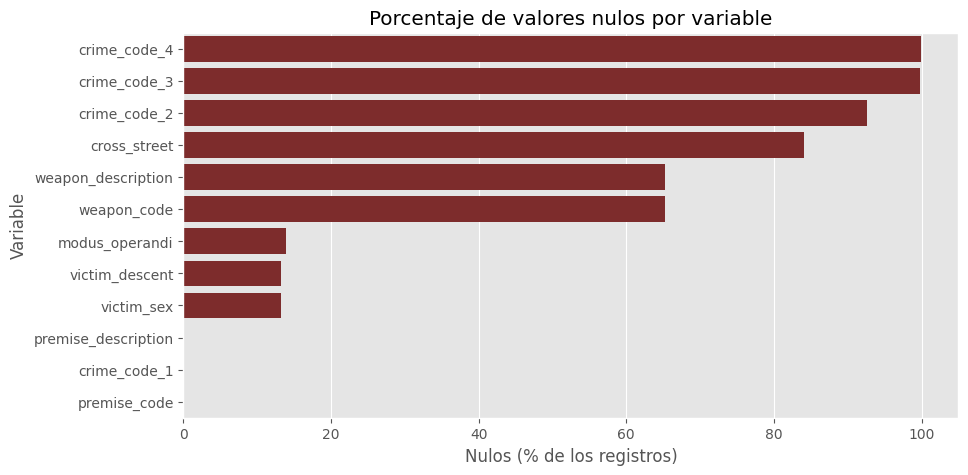

In [31]:
# Gráfico del % de nulos por variable (Seaborn)
plt.figure(figsize=(10, 5))
sns.barplot(x=tabla_nulos["Porcentaje"], y=tabla_nulos.index, color="#8B1E1E")
plt.title("Porcentaje de valores nulos por variable")
plt.xlabel("Nulos (% de los registros)")
plt.ylabel("Variable")
plt.show()

In [32]:
# Registros duplicados
df.duplicated().sum()

np.int64(0)

In [33]:
# Inconsistencias en sexo: el LAPD solo documenta F, M y X
df["victim_sex"].value_counts(dropna=False)

,count
victim_sex,
M,351362
F,313468
NaN,112606
X,75420
H,93
-,1


In [34]:
# Edades imposibles o sospechosas
print("Edad = 0:", (df["victim_age"] == 0).sum())
print("Edad negativa:", (df["victim_age"] < 0).sum())
print("Edad máxima:", df["victim_age"].max())

# ¿Qué delitos tienen edad 0?
df[df["victim_age"] == 0]["crime_description"].value_counts().head(5)

Edad = 0: 211842
Edad negativa: 74
Edad máxima: 120


,count
crime_description,
VEHICLE - STOLEN,91191
THEFT FROM MOTOR VEHICLE - PETTY ($950 & UNDER),18467
BURGLARY,16270
SHOPLIFTING - PETTY THEFT ($950 & UNDER),13813
"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)",12756


In [35]:
# Coordenadas inválidas: (0,0) es ubicación faltante según el LAPD; se revisan también nulos
print("Coordenadas (0,0):", ((df["latitude"] == 0) & (df["longitude"] == 0)).sum())
print("Coordenadas nulas:", df["latitude"].isnull().sum() + df["longitude"].isnull().sum())

# Horas por defecto: 12:00 y 00:01 exactas
print("A las 12:00:", ((df["date_occurred"].dt.hour == 12) & (df["date_occurred"].dt.minute == 0)).sum())
print("A las 00:01:", ((df["date_occurred"].dt.hour == 0) & (df["date_occurred"].dt.minute == 1)).sum())

# Valores fuera de rango: fechas y coordenadas
print("Fecha del hecho:", df["date_occurred"].min(), "a", df["date_occurred"].max())
print("Denuncias anteriores al hecho:", (df["date_reported"] < df["date_occurred"].dt.normalize()).sum())
validas = df[(df["latitude"] != 0) & (df["longitude"] != 0)]
print("Coordenadas fuera de Los Ángeles (lat 33,6-34,4 / lon -118,8 a -118,0):",
      ((validas["latitude"] < 33.6) | (validas["latitude"] > 34.4) |
       (validas["longitude"] < -118.8) | (validas["longitude"] > -118.0)).sum())

Coordenadas (0,0): 2263
Coordenadas nulas: 0
A las 12:00: 30235
A las 00:01: 14838
Fecha del hecho: 2020-01-01 00:01:00 a 2023-12-04 23:00:00
Denuncias anteriores al hecho: 0
Coordenadas fuera de Los Ángeles (lat 33,6-34,4 / lon -118,8 a -118,0): 0


### Decisiones de limpieza
| Problema | Decisión | Fundamento |
|---|---|---|
| Arma vacía (65,2%) | Rellenar con "Sin arma" | El vacío indica que no se usó arma |
| Sexo, origen y lugar vacíos | Rellenar con "Sin dato" | No se puede inferir; queda explícito |
| Sexo "H" y "-" | Reagrupar en "X" | No están en el diccionario del LAPD |
| Edad 0 o negativa | Excluir solo en el análisis de edad (`df_edad`) | Delitos sin una persona como víctima |
| Coordenadas (0,0) | Excluir solo en mapas (`df_mapa`) | El LAPD las define como ubicación faltante |
| Fechas y coordenadas fuera de rango | Ninguna acción | 0 casos: las fechas van del 1-ene-2020 al 4-dic-2023, ninguna denuncia es anterior al hecho y todas las coordenadas válidas caen dentro de la ciudad |
| Horas 12:00 y 00:01 exactas | Conservar y señalar en el Bloque 6 | Son horas por defecto; eliminarlas borraría 45.000 delitos reales |

No se elimina ninguna columna.

In [36]:
# Copias ANTES de limpiar, para la comparación antes/después
edad_antes = df["victim_age"].copy()
arma_antes = df["weapon_description"].copy()

# Reagrupar categorías no documentadas
df["victim_sex"] = df["victim_sex"].replace({"H": "X", "-": "X"})
df["victim_descent"] = df["victim_descent"].replace({"-": "X"})

# Nulos con significado -> categoría explícita
df["weapon_description"] = df["weapon_description"].cat.add_categories("Sin arma").fillna("Sin arma")
df["victim_sex"] = df["victim_sex"].cat.add_categories("Sin dato").fillna("Sin dato")
df["victim_descent"] = df["victim_descent"].cat.add_categories("Sin dato").fillna("Sin dato")
df["premise_description"] = df["premise_description"].cat.add_categories("Sin dato").fillna("Sin dato")

# Subconjuntos para análisis específicos
df_edad = df[df["victim_age"] > 0]                                 # solo víctimas persona
df_mapa = df[(df["latitude"] != 0) & (df["longitude"] != 0)]        # solo ubicación válida
print("df_edad:", df_edad.shape, "| df_mapa:", df_mapa.shape)

df_edad: (641034, 27) | df_mapa: (850687, 27)


### Antes y después de la limpieza

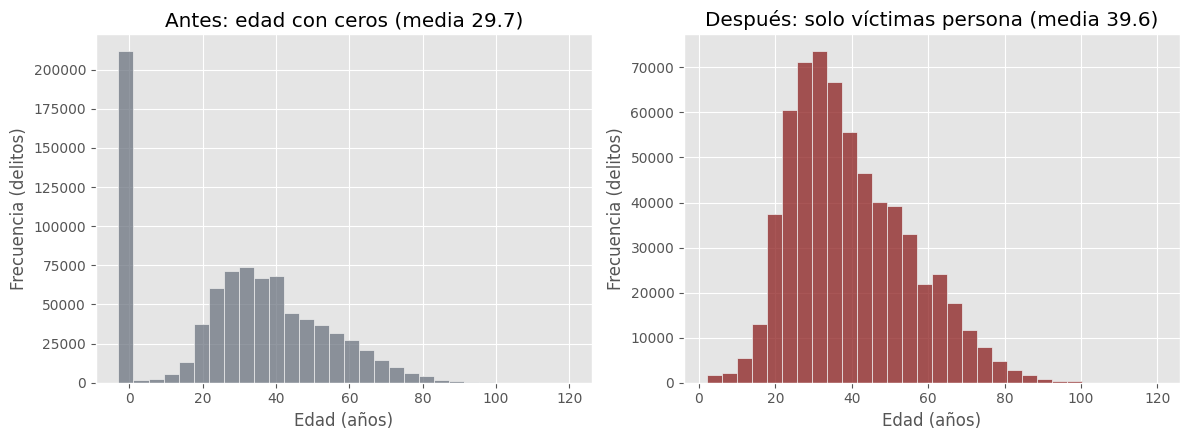

In [37]:
# Antes/después 1: edad con y sin los ceros (figura de dos paneles)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(x=edad_antes, bins=30, ax=axes[0], color="#6c7480")
axes[0].set_title("Antes: edad con ceros (media " + str(round(edad_antes.mean(), 1)) + ")")
axes[0].set_xlabel("Edad (años)")
axes[0].set_ylabel("Frecuencia (delitos)")
sns.histplot(x=df_edad["victim_age"], bins=30, ax=axes[1], color="#8B1E1E")
axes[1].set_title("Después: solo víctimas persona (media " + str(round(df_edad["victim_age"].mean(), 1)) + ")")
axes[1].set_xlabel("Edad (años)")
axes[1].set_ylabel("Frecuencia (delitos)")
plt.tight_layout()
plt.show()

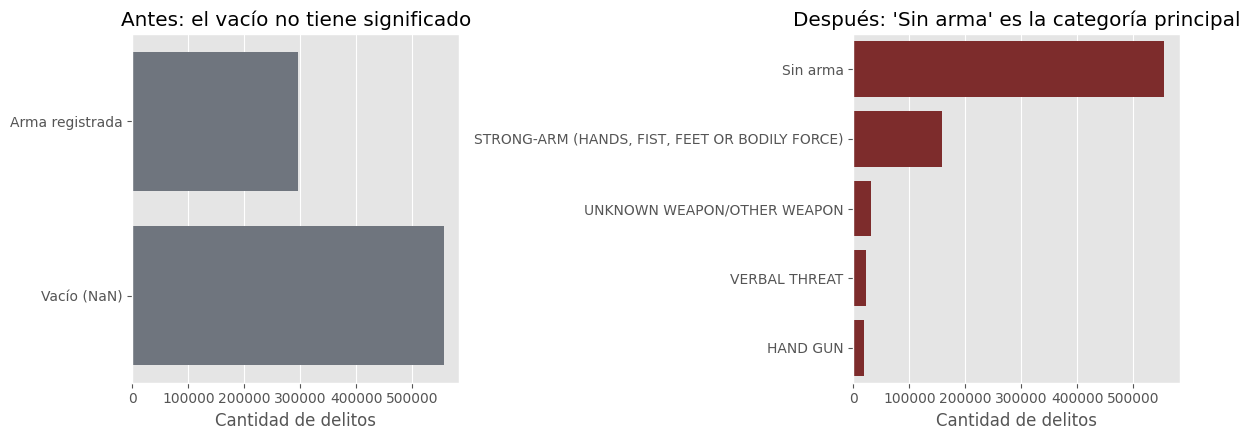

In [38]:
# Antes/después 2: arma con nulos vs con la categoría "Sin arma"
antes = pd.DataFrame({"Categoría": ["Arma registrada", "Vacío (NaN)"],
                      "Delitos": [arma_antes.notnull().sum(), arma_antes.isnull().sum()]})
despues = df["weapon_description"].astype("str").value_counts().head(5)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=antes, x="Delitos", y="Categoría", ax=axes[0], color="#6c7480")
axes[0].set_title("Antes: el vacío no tiene significado")
axes[0].set_xlabel("Cantidad de delitos")
axes[0].set_ylabel("")
sns.barplot(x=despues.values, y=despues.index, ax=axes[1], color="#8B1E1E")
axes[1].set_title("Después: 'Sin arma' es la categoría principal")
axes[1].set_xlabel("Cantidad de delitos")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

## Bloque 3 — Exploración univariada: ¿cómo se comporta cada variable?
*Feedback del Avance 2:* sin observaciones de contenido; histogramas, boxplots, KDE y barras pasan a Seaborn (`histplot`, `boxplot`, `kdeplot`, `countplot`).
Variable derivada: **retraso de la denuncia** = días entre el delito y su denuncia.

In [39]:
# Variable continua derivada: días entre el hecho y la denuncia
df["retraso_dias"] = (df["date_reported"] - df["date_occurred"].dt.normalize()).dt.days
df["retraso_dias"].head()

,retraso_dias
0,0
1,1
2,61
3,0
4,0


In [40]:
# Resumen de todas las variables numéricas (Clase 4), más moda y RIC
numericas_df = df[["victim_age", "latitude", "longitude", "retraso_dias"]]
resumen = numericas_df.describe().T
resumen["moda"] = numericas_df.mode().iloc[0]
resumen["RIC"] = resumen["75%"] - resumen["25%"]
resumen.round(2)

,count,mean,std,min,25%,50%,75%,max,moda,RIC
victim_age,852950.0,29.74,21.80,-3.00,5.00,31.00,45.00,120.00,0.00,40.00
latitude,852950.0,33.98,1.76,0.00,34.01,34.06,34.16,34.33,34.10,0.15
longitude,852950.0,-118.04,6.09,-118.67,-118.43,-118.32,-118.27,0.00,-118.27,0.16
retraso_dias,852950.0,10.69,58.51,0.00,0.00,1.00,2.00,1419.00,0.00,2.00


In [41]:
# Estadísticas de la edad (solo víctimas persona)
edad = df_edad["victim_age"]
p25 = edad.quantile(0.25)
p75 = edad.quantile(0.75)
print("Media:", round(edad.mean(), 2))
print("Mediana:", edad.median())
print("Moda:", edad.mode()[0])
print("Desviación estándar:", round(edad.std(), 2))
print("Mínimo:", edad.min(), "| Máximo:", edad.max())
print("P25:", p25, "| P75:", p75, "| RIC:", p75 - p25)
print("Asimetría:", round(edad.skew(), 2))

Media: 39.57
Mediana: 37.0
Moda: 30
Desviación estándar: 15.59
Mínimo: 2 | Máximo: 120
P25: 28.0 | P75: 50.0 | RIC: 22.0
Asimetría: 0.61


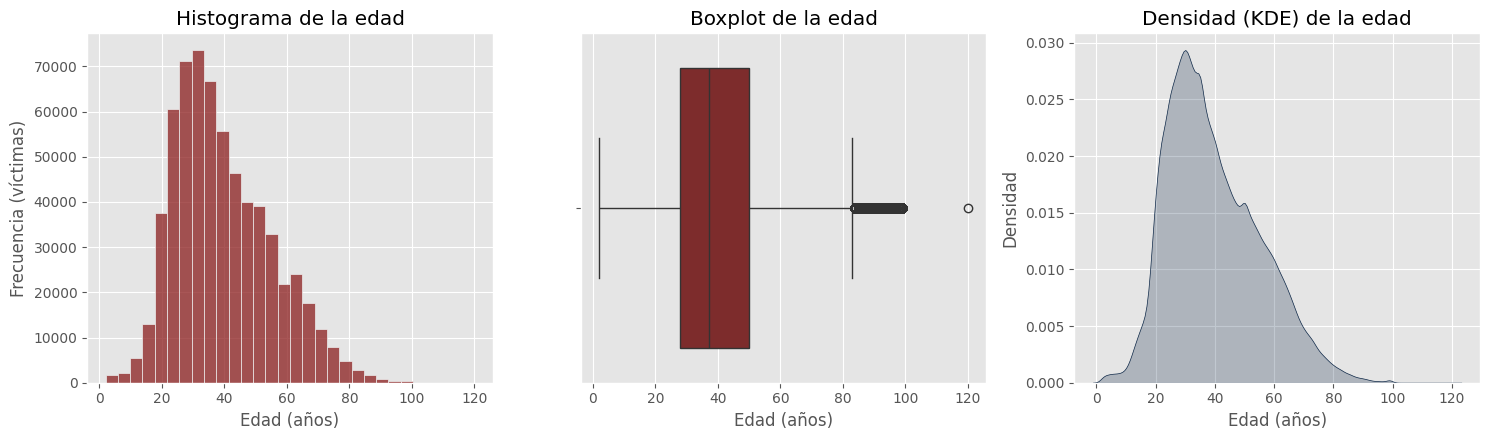

In [42]:
# Edad: histograma, boxplot y densidad (Seaborn)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sns.histplot(data=df_edad, x="victim_age", bins=30, ax=axes[0], color="#8B1E1E")
axes[0].set_title("Histograma de la edad")
axes[0].set_xlabel("Edad (años)")
axes[0].set_ylabel("Frecuencia (víctimas)")
sns.boxplot(data=df_edad, x="victim_age", ax=axes[1], color="#8B1E1E")
axes[1].set_title("Boxplot de la edad")
axes[1].set_xlabel("Edad (años)")
sns.kdeplot(data=df_edad, x="victim_age", fill=True, ax=axes[2], color="#0b2545")
axes[2].set_title("Densidad (KDE) de la edad")
axes[2].set_xlabel("Edad (años)")
axes[2].set_ylabel("Densidad")
plt.tight_layout()
plt.show()

**Lectura de la edad.** Distribución unimodal con asimetría leve hacia la derecha (0,61): la media (39,6) supera a la mediana (37). La mitad de las víctimas tiene entre 28 y 50 años. El boxplot marca atípicos sobre 83 años, que se analizan en el Bloque 5. Los picos en 30, 35 y 50 sugieren redondeo al registrar la edad.

In [43]:
# Estadísticas del retraso de la denuncia
retraso = df["retraso_dias"]
q25 = retraso.quantile(0.25)
q75 = retraso.quantile(0.75)
print("Media:", round(retraso.mean(), 2))
print("Mediana:", retraso.median())
print("Moda:", retraso.mode()[0])
print("Desviación estándar:", round(retraso.std(), 2))
print("Mínimo:", retraso.min(), "| Máximo:", retraso.max())
print("P25:", q25, "| P75:", q75, "| RIC:", q75 - q25)
print("Asimetría:", round(retraso.skew(), 2))
print("% denunciado el mismo día:", round((retraso == 0).mean() * 100, 1))
print("Casos con más de un año:", (retraso > 365).sum())

Media: 10.69
Mediana: 1.0
Moda: 0
Desviación estándar: 58.51
Mínimo: 0 | Máximo: 1419
P25: 0.0 | P75: 2.0 | RIC: 2.0
Asimetría: 11.26
% denunciado el mismo día: 49.3
Casos con más de un año: 5268


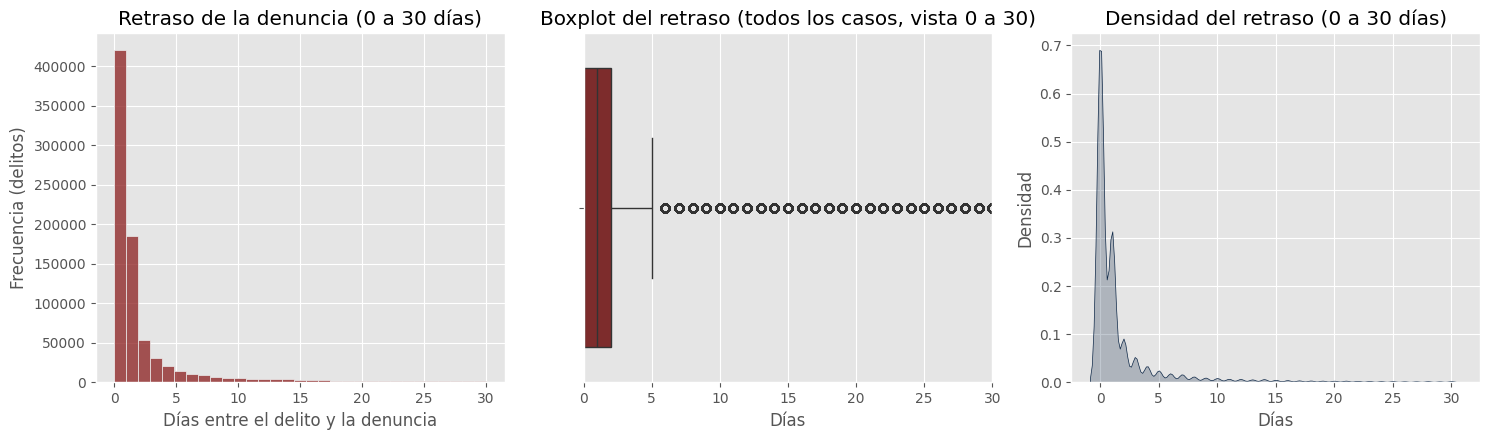

In [44]:
# Retraso: histograma (0 a 30 días, donde está la mayoría), boxplot y densidad
retraso_30 = df[df["retraso_dias"] <= 30]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sns.histplot(data=retraso_30, x="retraso_dias", bins=31, ax=axes[0], color="#8B1E1E")
axes[0].set_title("Retraso de la denuncia (0 a 30 días)")
axes[0].set_xlabel("Días entre el delito y la denuncia")
axes[0].set_ylabel("Frecuencia (delitos)")
sns.boxplot(data=df, x="retraso_dias", ax=axes[1], color="#8B1E1E")
axes[1].set_xlim(0, 30)  # solo se recorta la vista; el boxplot se calcula con todos los casos
axes[1].set_title("Boxplot del retraso (todos los casos, vista 0 a 30)")
axes[1].set_xlabel("Días")
sns.kdeplot(data=retraso_30, x="retraso_dias", fill=True, ax=axes[2], color="#0b2545")
axes[2].set_title("Densidad del retraso (0 a 30 días)")
axes[2].set_xlabel("Días")
axes[2].set_ylabel("Densidad")
plt.tight_layout()
plt.show()

**Lectura del retraso.** Distribución muy concentrada en 0 y extremadamente asimétrica (11,3): el 49,3% se denuncia el mismo día y el 77,3% dentro de dos días, pero la cola llega a 1.419 días. Por eso la mediana (1 día) describe mejor el caso típico que la media (10,7). El boxplot se muestra con la vista recortada a 30 días; con el eje completo la caja se vería como una raya.

In [45]:
# Variables categóricas: categorías únicas y proporciones (%)
for col in ["crime_description", "premise_description", "weapon_description",
            "area_name", "victim_sex", "status_description"]:
    print(col, "| categorías únicas:", df[col].nunique())
    print((df[col].value_counts() / len(df) * 100).round(1).head(3))
    print()

crime_description | categorías únicas: 138
crime_description
VEHICLE - STOLEN            10.7
BATTERY - SIMPLE ASSAULT     8.0
THEFT OF IDENTITY            6.3
Name: count, dtype: float64

premise_description | categorías únicas: 307
premise_description
STREET                                          25.3
SINGLE FAMILY DWELLING                          16.9
MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)    12.2
Name: count, dtype: float64

weapon_description | categorías únicas: 80
weapon_description
Sin arma                                          65.2
STRONG-ARM (HANDS, FIST, FEET OR BODILY FORCE)    18.6
UNKNOWN WEAPON/OTHER WEAPON                        3.7
Name: count, dtype: float64

area_name | categorías únicas: 21
area_name
Central        6.8
77th Street    6.3
Pacific        5.8
Name: count, dtype: float64

victim_sex | categorías únicas: 4
victim_sex
M           41.2
F           36.8
Sin dato    13.2
Name: count, dtype: float64

status_description | categorías únicas: 6
statu

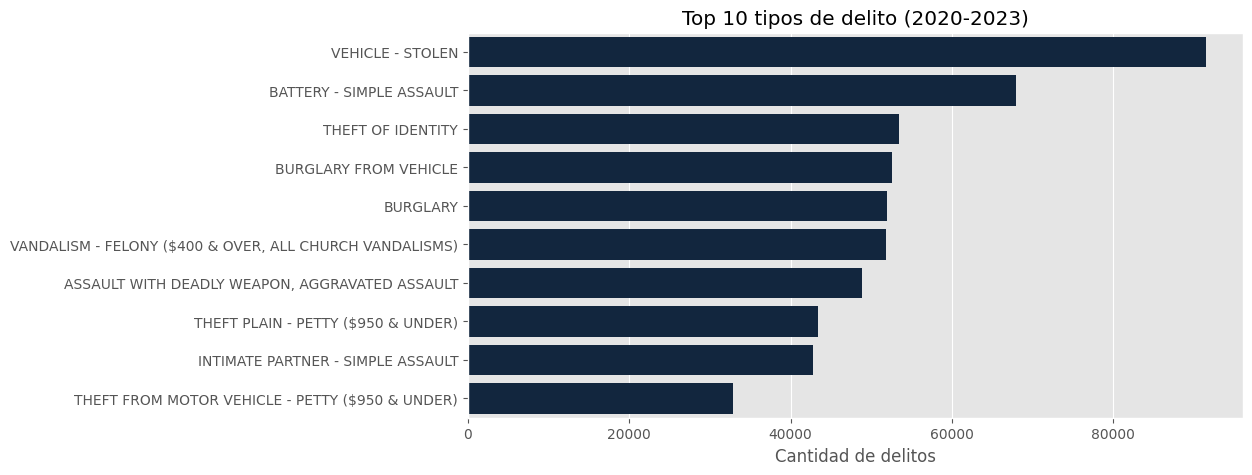

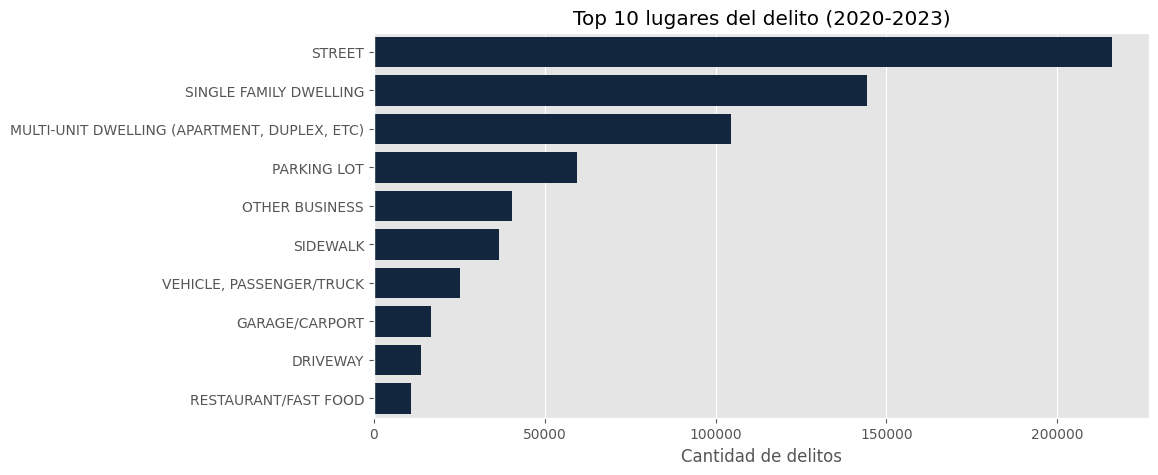

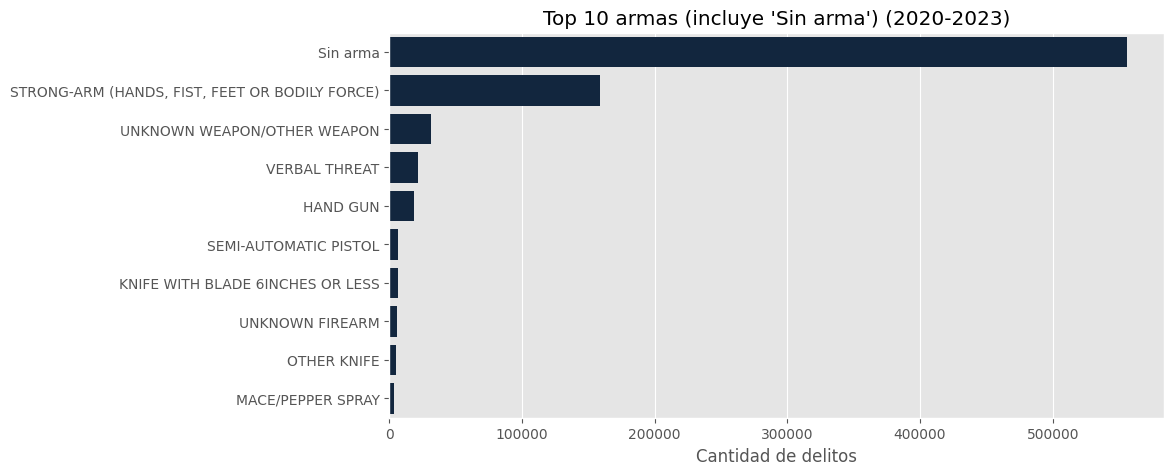

In [46]:
# Countplot top 10: tipo de delito, lugar y arma (Seaborn)
for col, titulo in [("crime_description", "Top 10 tipos de delito"),
                    ("premise_description", "Top 10 lugares del delito"),
                    ("weapon_description", "Top 10 armas (incluye 'Sin arma')")]:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, y=col, order=df[col].value_counts().head(10).index, color="#0b2545")
    plt.title(titulo + " (2020-2023)")
    plt.xlabel("Cantidad de delitos")
    plt.ylabel("")
    plt.show()

**Lectura de las categóricas.** Las tres variables están muy concentradas: el robo de vehículo es el delito más frecuente (10,7%) y el top 10 reúne cerca del 63% de los casos; la calle (25,3%) y la vivienda unifamiliar (16,9%) suman más del 40% de los lugares; y "Sin arma" domina con 65,2%, seguida de la fuerza física (18,6%). Las armas de fuego son minoritarias. Con 138, 307 y 80 categorías respectivamente, el top 10 es la forma legible de mostrarlas.

## Bloque 4 — Mapas: ¿dónde ocurre el delito?
*Feedback del Avance 2:* sin observaciones de contenido; los mapas se rehacen en Seaborn (`scatterplot` y `kdeplot`) con ejes en proporción y recuadro acotado.
Se usan los 850.687 delitos con coordenadas válidas (`df_mapa`): se excluyeron las 2.263 coordenadas (0,0) y no hay coordenadas nulas.

In [47]:
# Muestra de 100.000 delitos: la pauta la pide sobre 100.000 puntos (tenemos 850.687)
muestra = df_mapa.sample(100000, random_state=42)

# ¿La muestra representa al total? Comparamos proporciones (puntos porcentuales)
print("Diferencia máxima por área:",
      round(((df_mapa["area_name"].value_counts(normalize=True) - muestra["area_name"].value_counts(normalize=True)).abs().max() * 100), 2), "pp")
print("Diferencia máxima por gravedad:",
      round(((df_mapa["part"].value_counts(normalize=True) - muestra["part"].value_counts(normalize=True)).abs().max() * 100), 2), "pp")

Diferencia máxima por área: 0.14 pp
Diferencia máxima por gravedad: 0.07 pp


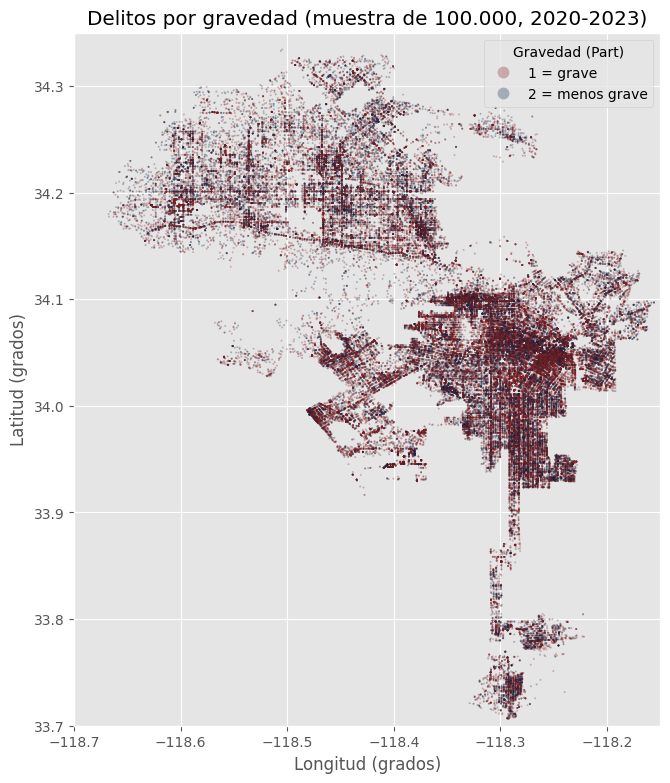

In [48]:
# Mapa de puntos: muestra de 100.000 coloreada por gravedad (1 = grave, 2 = menos grave)
fig, ax = plt.subplots(figsize=(9, 9))
sns.scatterplot(data=muestra, x="longitude", y="latitude", hue="part",
                palette={1: "#8B1E1E", 2: "#0b2545"}, s=2, alpha=0.3, linewidth=0, ax=ax)
ax.set_aspect("equal")
ax.set_xlim(-118.70, -118.15)
ax.set_ylim(33.70, 34.35)
ax.set_title("Delitos por gravedad (muestra de 100.000, 2020-2023)")
ax.set_xlabel("Longitud (grados)")
ax.set_ylabel("Latitud (grados)")
handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["1 = grave", "2 = menos grave"], title="Gravedad (Part)", markerscale=6)
plt.show()

**Interpretación del mapa de puntos.** *Dónde se concentra:* en el centro-sur de la ciudad (Central, 77th Street, Southwest) y en el corredor de Hollywood, donde la trama de puntos es más densa. *Dónde no:* el Valle de San Fernando (norte) aparece disperso, y las laderas de Santa Mónica y la franja de Harbor (sur) casi vacías. *Qué implica:* los delitos graves (Part 1, 58,8%) y los menos graves (41,2%) se mezclan en toda la ciudad, sin zonas "solo graves"; la prioridad de patrullaje debe fijarse por volumen, no por tipo de zona.

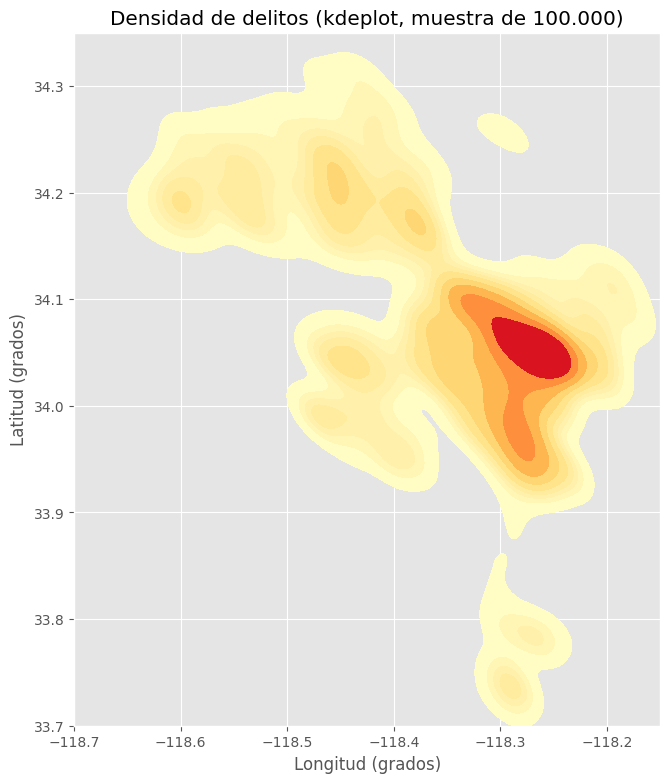

In [49]:
# Mapa de densidad: kdeplot sobre la misma muestra de 100.000
fig, ax = plt.subplots(figsize=(9, 9))
sns.kdeplot(data=muestra, x="longitude", y="latitude", fill=True, cmap="YlOrRd",
            levels=10, thresh=0.05, ax=ax)
ax.set_aspect("equal")
ax.set_xlim(-118.70, -118.15)
ax.set_ylim(33.70, 34.35)
ax.set_title("Densidad de delitos (kdeplot, muestra de 100.000)")
ax.set_xlabel("Longitud (grados)")
ax.set_ylabel("Latitud (grados)")
plt.show()

**Interpretación del mapa de densidad.** *Dónde se concentra:* la zona más densa es un núcleo compacto en Downtown/Central, que se extiende hacia Hollywood al noroeste y hacia 77th Street al sur; Central tiene 57.497 delitos y Foothill, el área con menos, 28.301 (el doble). *Dónde no:* el resto de la ciudad aparece en tonos claros o sin color (densidad bajo el 5% del máximo). *Qué implica:* cerca del 30% de los delitos ocurre en cinco áreas; un tercio del esfuerzo preventivo puede concentrarse ahí. El mapa se construyó con la muestra de 100.000 porque `kdeplot` con 850.687 puntos es inviable en Colab y la muestra reproduce las proporciones del total.

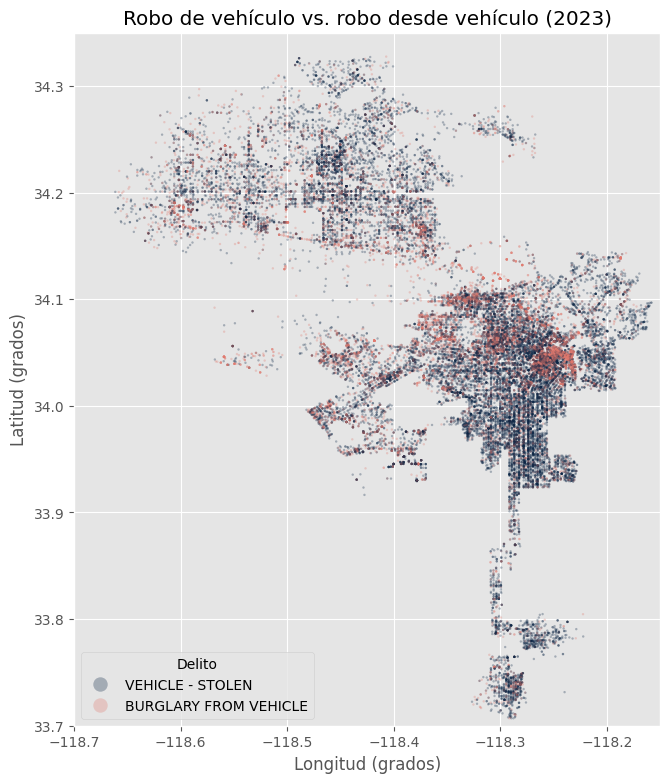

In [50]:
# Mapa de puntos: dos delitos de vehículos en 2023 (34.505 < 100.000, no requiere muestra)
dos = ["VEHICLE - STOLEN", "BURGLARY FROM VEHICLE"]
df_dos = df_mapa[(df_mapa["crime_description"].isin(dos)) &
                 (df_mapa["date_occurred"].dt.year == 2023)]
fig, ax = plt.subplots(figsize=(9, 9))
sns.scatterplot(data=df_dos, x="longitude", y="latitude", hue="crime_description",
                hue_order=dos, palette=["#0b2545", "#e07a6f"], s=3, alpha=0.3, linewidth=0, ax=ax)
ax.set_aspect("equal")
ax.set_xlim(-118.70, -118.15)
ax.set_ylim(33.70, 34.35)
ax.set_title("Robo de vehículo vs. robo desde vehículo (2023)")
ax.set_xlabel("Longitud (grados)")
ax.set_ylabel("Latitud (grados)")
ax.legend(title="Delito", markerscale=6)
plt.show()

**Interpretación del mapa de dos delitos.** *Dónde se concentra:* el robo desde vehículo (rojo) se agrupa en Central (15,3% de sus casos), Hollywood y Pacific, zonas de comercio y estacionamientos; el robo de vehículo (azul) se reparte de forma más pareja, con máximos en 77th Street (7,7%), Newton y Southeast, zonas residenciales del sur. *Dónde no:* ninguno de los dos pesa en Foothill ni en las laderas. *Qué implica:* dos estrategias distintas: vigilancia de estacionamientos en el centro y prevención residencial en el sur. Con 34.505 puntos (menos de 100.000) no se requiere muestra.

In [51]:
# Cifras para interpretar los mapas
print("Delitos por área (top 5 y mínimo):")
print(df_mapa["area_name"].value_counts().head(5))
print(df_mapa["area_name"].value_counts().tail(1))
print("\nGravedad (%):")
print((df_mapa["part"].value_counts(normalize=True) * 100).round(1))

robo_desde = df_mapa[df_mapa["crime_description"] == "BURGLARY FROM VEHICLE"]
robo_de = df_mapa[df_mapa["crime_description"] == "VEHICLE - STOLEN"]
print("\nRobo desde vehículo (% por área):")
print((robo_desde["area_name"].value_counts() / len(robo_desde) * 100).round(1).head(3))
print("\nRobo de vehículo (% por área):")
print((robo_de["area_name"].value_counts() / len(robo_de) * 100).round(1).head(3))

Delitos por área (top 5 y mínimo):
area_name
Central        57497
77th Street    53494
Pacific        49677
Southwest      47793
Hollywood      44696
Name: count, dtype: int64
area_name
Foothill    28301
Name: count, dtype: int64

Gravedad (%):
part
1    58.8
2    41.2
Name: proportion, dtype: float64

Robo desde vehículo (% por área):
area_name
Central      15.3
Hollywood     6.9
Pacific       6.2
Name: count, dtype: float64

Robo de vehículo (% por área):
area_name
77th Street    7.7
Newton         7.3
Southeast      6.3
Name: count, dtype: float64


## Bloque 5 — Valores atípicos: ¿qué valores se salen de lo esperado?
*Bloque nuevo del Certamen 2.*

Regla IQR: es atípico todo valor bajo Q1 − 1,5·RIC o sobre Q3 + 1,5·RIC. Se aplica a las variables numéricas: edad (`df_edad`), retraso de la denuncia, latitud y longitud (`df_mapa`) y hora del hecho.

In [52]:
# Hora del hecho como variable numérica
df["hora"] = df["date_occurred"].dt.hour

# Regla IQR para cada variable numérica
variables = [("victim_age", df_edad), ("retraso_dias", df), ("latitude", df_mapa),
             ("longitude", df_mapa), ("hora", df)]
filas = []
for col, datos in variables:
    q1 = datos[col].quantile(0.25)
    q3 = datos[col].quantile(0.75)
    ric = q3 - q1
    lim_inf = q1 - 1.5 * ric
    lim_sup = q3 + 1.5 * ric
    n_atip = ((datos[col] < lim_inf) | (datos[col] > lim_sup)).sum()
    filas.append({"Variable": col, "Q1": q1, "Q3": q3, "RIC": ric,
                  "Límite inferior": lim_inf, "Límite superior": lim_sup,
                  "Atípicos": n_atip, "% atípicos": round(n_atip / len(datos) * 100, 1)})
tabla_atipicos = pd.DataFrame(filas)
tabla_atipicos.round(2)

,Variable,Q1,Q3,RIC,Límite inferior,Límite superior,Atípicos,% atípicos
0,victim_age,28.00,50.00,22.00,-5.00,83.00,3875,0.6
1,retraso_dias,0.00,2.00,2.00,-3.00,5.00,128706,15.1
2,latitude,34.01,34.16,0.15,33.79,34.39,25704,3.0
3,longitude,-118.43,-118.27,0.16,-118.66,-118.04,33,0.0
4,hora,9.00,19.00,10.00,-6.00,34.00,0,0.0


In [53]:
# Diagnóstico: ¿qué hay detrás de los atípicos?
print("Edad sobre 83 años, delitos más frecuentes:")
print(df_edad[df_edad["victim_age"] > 83]["crime_description"].value_counts().head(3))
print("\nVíctimas con edad 99:", (df_edad["victim_age"] == 99).sum())
print("\nRetraso sobre 5 días, delitos más frecuentes (%):")
print((df[df["retraso_dias"] > 5]["crime_description"].value_counts(normalize=True) * 100).round(1).head(3))
print("\nLatitud bajo 33,79 (franja sur), áreas:")
print(df_mapa[df_mapa["latitude"] < 33.79]["area_name"].value_counts().head(3))

Edad sobre 83 años, delitos más frecuentes:
crime_description
BURGLARY                    611
THEFT OF IDENTITY           417
BATTERY - SIMPLE ASSAULT    384
Name: count, dtype: int64

Víctimas con edad 99: 311

Retraso sobre 5 días, delitos más frecuentes (%):
crime_description
THEFT OF IDENTITY                                           21.6
THEFT PLAIN - PETTY ($950 & UNDER)                           9.1
THEFT-GRAND ($950.01 & OVER)EXCPT,GUNS,FOWL,LIVESTK,PROD     6.8
Name: proportion, dtype: float64

Latitud bajo 33,79 (franja sur), áreas:
area_name
Harbor         25169
77th Street        0
Central            0
Name: count, dtype: int64


**Decisión: se mantienen todos los atípicos.** Son valores reales del dominio: adultos mayores víctimas de robo a vivienda y de identidad, robos de identidad que se descubren semanas después y la franja sur de la ciudad (Harbor), que la regla IQR marca solo por la forma alargada de Los Ángeles. Eliminarlos borraría casos relevantes para la policía. El gráfico siguiente muestra qué se perdería si se eliminaran.

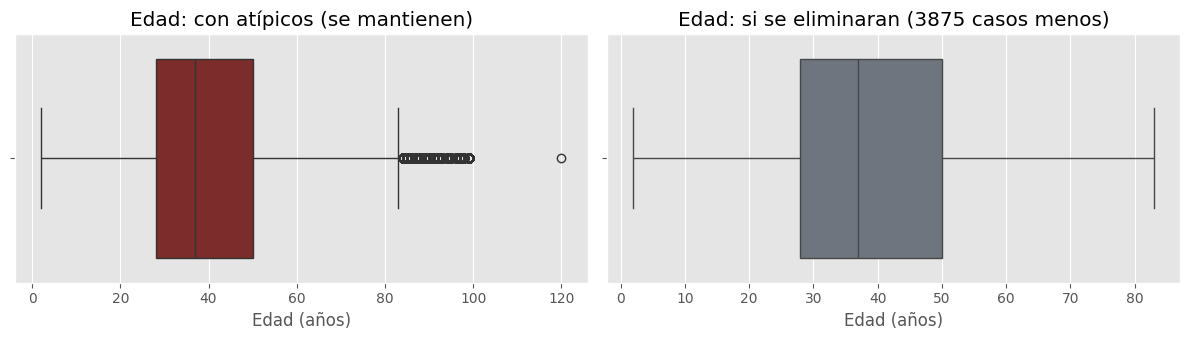

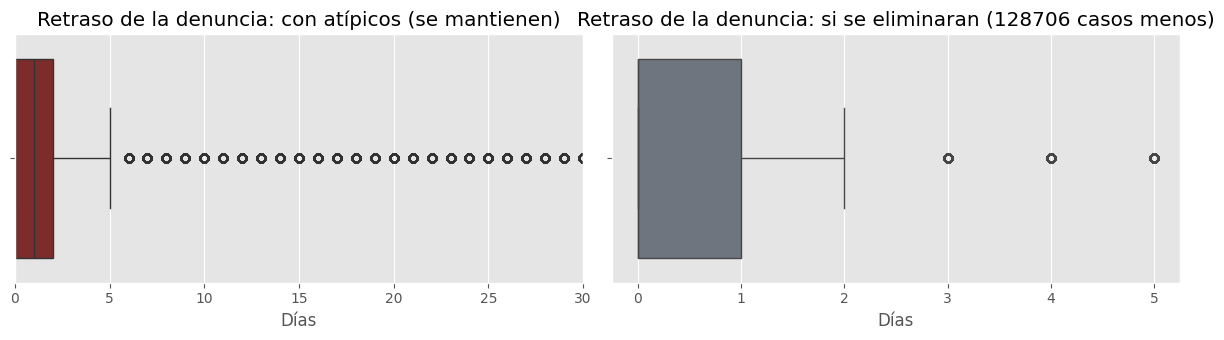

In [54]:
# Boxplot antes/después: distribución con atípicos (decisión) vs. si se eliminaran
for col, datos, unidad, nombre in [("victim_age", df_edad, "Edad (años)", "Edad"),
                                   ("retraso_dias", df, "Días", "Retraso de la denuncia")]:
    fila = tabla_atipicos[tabla_atipicos["Variable"] == col]
    lim_sup = fila["Límite superior"].values[0]
    sin_atipicos = datos[datos[col] <= lim_sup]
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
    sns.boxplot(data=datos, x=col, ax=axes[0], color="#8B1E1E")
    axes[0].set_title(nombre + ": con atípicos (se mantienen)")
    axes[0].set_xlabel(unidad)
    if col == "retraso_dias":
        axes[0].set_xlim(0, 30)  # vista 0 a 30 días; los casos sobre 30 siguen en los datos
    sns.boxplot(data=sin_atipicos, x=col, ax=axes[1], color="#6c7480")
    axes[1].set_title(nombre + ": si se eliminaran (" + str(len(datos) - len(sin_atipicos)) + " casos menos)")
    axes[1].set_xlabel(unidad)
    plt.tight_layout()
    plt.show()

**Lectura.** Si se eliminaran los atípicos, la edad perdería 3.875 víctimas mayores de 83 años y el retraso 128.706 denuncias con más de 5 días (15,1%), entre ellas la mayoría de los robos de identidad. La distribución quedaría más "limpia" pero menos fiel al fenómeno: por eso se mantienen todos.

## Bloque 6 — Exploración temporal: ¿cómo cambian los datos en el tiempo?
*Bloque nuevo del Certamen 2.*

Se excluye diciembre de 2023 (los datos terminan el 4 de diciembre: 1.545 delitos) para no mostrar una caída falsa. Las 12:00 se señalan como hora por defecto.

In [55]:
# Variables de tiempo y corte en noviembre de 2023
df["anio"] = df["date_occurred"].dt.year
df["mes"] = df["date_occurred"].dt.month
df_tiempo = df[~((df["anio"] == 2023) & (df["mes"] == 12))]
print("Diciembre 2023 excluido:", len(df) - len(df_tiempo), "delitos")

# Delitos por año y mes
mensual = df_tiempo.groupby(["anio", "mes"]).size().reset_index(name="delitos")
mensual.sort_values("delitos").head(3)

Diciembre 2023 excluido: 1545 delitos


,anio,mes,delitos
13,2021,2,15411
10,2020,11,15574
8,2020,9,15639


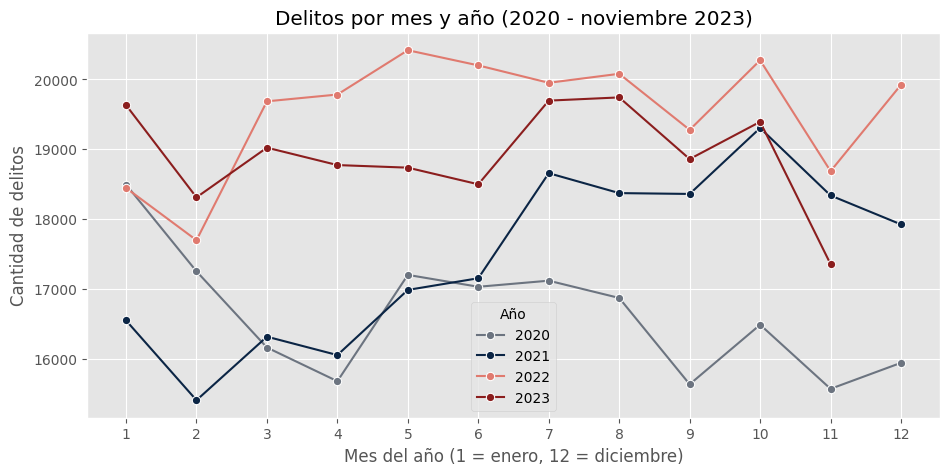

In [56]:
# Lineplot: delitos por mes, una línea por año
plt.figure(figsize=(11, 5))
sns.lineplot(data=mensual, x="mes", y="delitos", hue="anio", marker="o", palette=["#6c7480", "#0b2545", "#e07a6f", "#8B1E1E"])
plt.title("Delitos por mes y año (2020 - noviembre 2023)")
plt.xlabel("Mes del año (1 = enero, 12 = diciembre)")
plt.ylabel("Cantidad de delitos")
plt.xticks(range(1, 13))
plt.legend(title="Año")
plt.show()

### Lectura con el contexto de la pandemia
Las fechas de las restricciones por COVID-19 en Los Ángeles ayudan a leer la curva mensual (fuentes al final del bloque):

| Fecha | Hito | Qué muestra el dataset |
|---|---|---|
| 19-mar-2020 | Orden "Safer at Home" (ciudad, condado y estado) | Abril de 2020 es el mes más bajo del período: 15.683 delitos. Entre el 20 de marzo y el 7 de mayo se registraron 515 delitos por día, un 14% menos que en enero-febrero de 2020 (596 por día). |
| 13-jul-2020 y 6-dic-2020 | Retroceso de la reapertura y segundo confinamiento regional | El segundo semestre de 2020 y el inicio de 2021 se mantienen bajos: entre 523 y 532 delitos por día. Febrero de 2021 (15.411) es el mínimo entre los meses completos. |
| 15-jun-2021 | Reapertura total de California (fin del sistema de niveles) | El alza empieza al mes siguiente: de 17.156 delitos en junio a 18.659 en julio de 2021, y 2021 cierra sobre 2020. |
| 4-mar-2022 | Fin de la mascarilla obligatoria en interiores | 2022 es el año máximo (234.436), con 643 delitos por día entre marzo de 2022 y marzo de 2023. |
| 31-mar-2023 | Fin de la emergencia sanitaria del condado | 2023 se estabiliza algo más abajo: 619 delitos por día entre abril y noviembre. |

No todos los delitos reaccionaron igual al confinamiento. Comparando abril con febrero de 2020: el hurto en tiendas cayó 52%, el hurto simple 31%, el robo con violencia 22% y la agresión simple 17%; en cambio, el robo de vehículos subió 44% (de 1.280 a 1.837) y siguió subiendo hasta 2.090 en junio de 2020. Esto coincide con lo reportado por la prensa local: menos delitos con gente en la calle y más autos robados mientras estaban estacionados.

**Límites de esta lectura:** el dataset empieza en enero de 2020, por lo que no existe un 2019 "normal" con el cual comparar; las cifras del LAPD se revisan con el tiempo, así que no coinciden exactamente con las publicadas en prensa; y la coincidencia en el tiempo no demuestra causa, solo la describe.

*Fuentes de las fechas:* LAist (guía de restricciones 2020 y fin de la mascarilla, 4-mar-2022) · The Eastsider (orden Safer at Home) · Manatt (retroceso del 13-jul-2020) · Los Angeles Magazine (orden regional de diciembre 2020) · NBC Palm Springs (fin de la orden regional, 25-ene-2021) · ABC7 (reapertura 15-jun-2021 y fin de la emergencia 31-mar-2023) · Oficina de la supervisora Janice Hahn, Condado de LA · Crosstown LA (análisis de delitos 2020, 2021 y 2022).

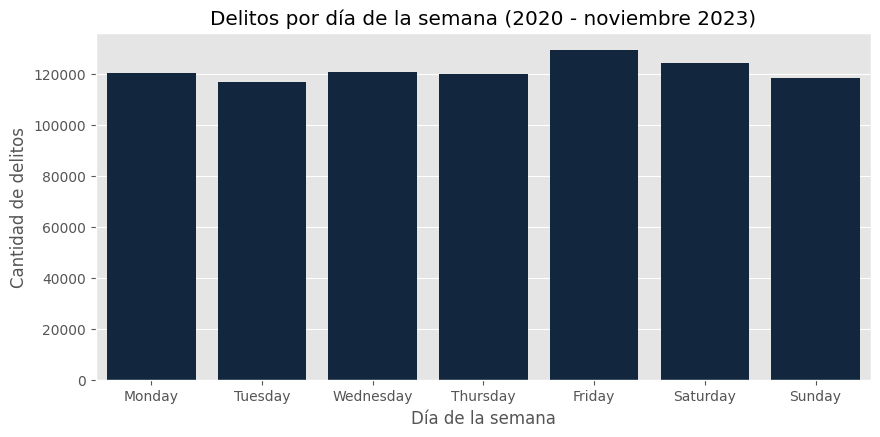

,count
dia,
Monday,120509
Tuesday,117006
Wednesday,121114
Thursday,120213
Friday,129690
Saturday,124288
Sunday,118585


In [57]:
# Barplot: delitos por día de la semana
dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df_tiempo["dia"] = df_tiempo["date_occurred"].dt.day_name()
por_dia = df_tiempo["dia"].value_counts().reindex(dias)
plt.figure(figsize=(10, 4.5))
sns.barplot(x=por_dia.index, y=por_dia.values, color="#0b2545")
plt.title("Delitos por día de la semana (2020 - noviembre 2023)")
plt.xlabel("Día de la semana")
plt.ylabel("Cantidad de delitos")
plt.show()
por_dia

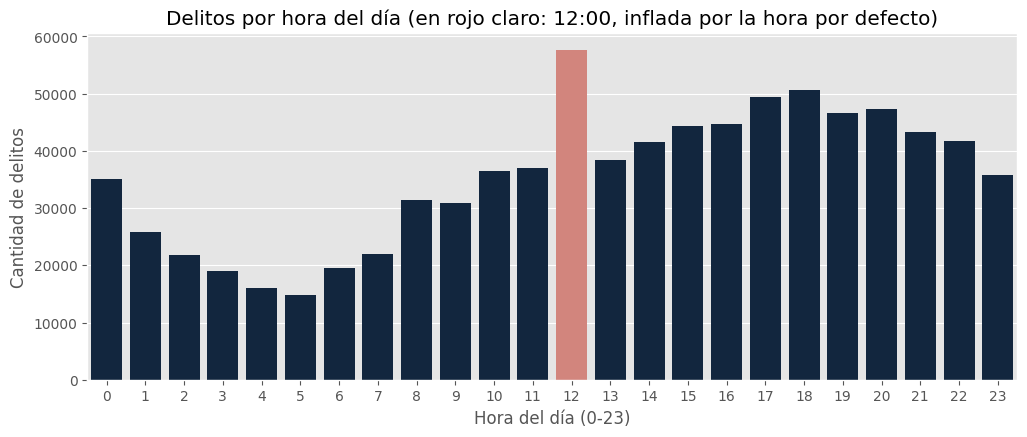

In [58]:
# Barplot: delitos por hora, con las 12:00 señaladas (hora por defecto)
por_hora = df_tiempo["hora"].value_counts().sort_index()
colores = ["#e07a6f" if h == 12 else "#0b2545" for h in por_hora.index]
plt.figure(figsize=(12, 4.5))
sns.barplot(x=por_hora.index, y=por_hora.values, palette=colores)
plt.title("Delitos por hora del día (en rojo claro: 12:00, inflada por la hora por defecto)")
plt.xlabel("Hora del día (0-23)")
plt.ylabel("Cantidad de delitos")
plt.show()

**Lectura del día y la hora.** Por día de la semana la variación es moderada: el viernes es el máximo (129.690) y el martes el mínimo (117.006), un 10,8% de diferencia. Por hora, el mínimo es a las 5:00 (14.829) y la franja alta va de 15:00 a 20:00, con el máximo real a las 18:00 (50.606). La barra de las 12:00 (57.683) está inflada por los 30.217 delitos registrados exactamente a esa hora, la hora por defecto cuando no se conoce la real: se señala en el gráfico y no se usa para concluir.

## Bloque 7 — Relaciones entre variables: ¿qué variables se mueven juntas?
*Bloque nuevo del Certamen 2.*

Numéricas: edad, retraso, hora, latitud y longitud (víctimas persona con ubicación válida). Grupos: los 5 delitos más frecuentes.

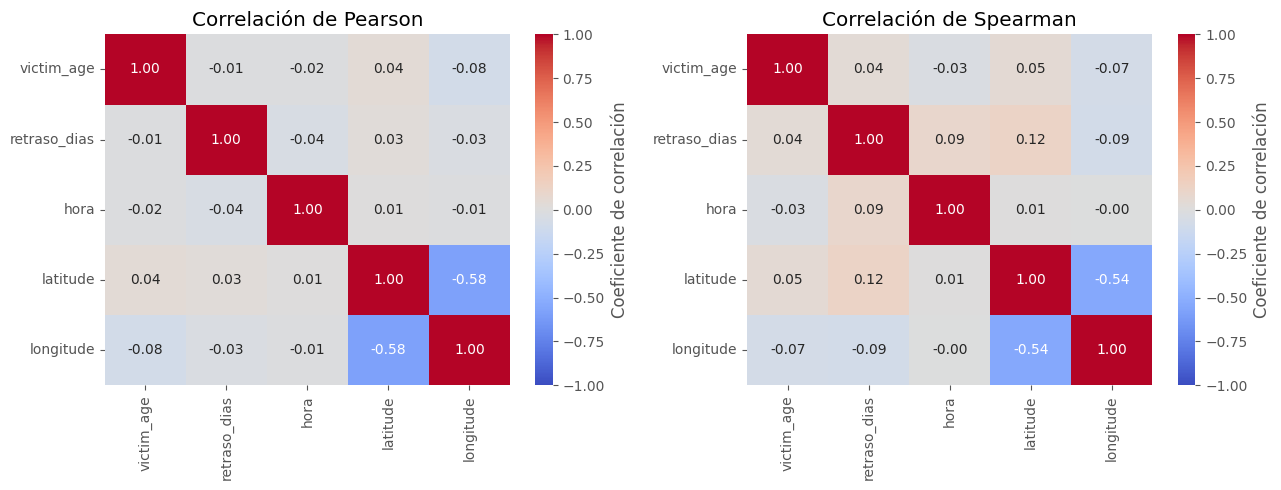

In [59]:
# Base para relaciones numéricas: víctimas persona con ubicación válida
base = df[(df["victim_age"] > 0) & (df["latitude"] != 0) & (df["longitude"] != 0)]
numericas = ["victim_age", "retraso_dias", "hora", "latitude", "longitude"]

# Heatmap de correlación (Pearson y Spearman)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(base[numericas].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0],
            cbar_kws={"label": "Coeficiente de correlación"})
axes[0].set_title("Correlación de Pearson")
sns.heatmap(base[numericas].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1],
            cbar_kws={"label": "Coeficiente de correlación"})
axes[1].set_title("Correlación de Spearman")
plt.tight_layout()
plt.show()

**Lectura de las correlaciones.** Como medida descriptiva, las variables numéricas no se mueven juntas: todos los coeficientes están entre −0,09 y 0,12, tanto en Pearson (lineal) como en Spearman (por rangos, resistente a los atípicos del retraso). La única excepción es latitud-longitud (−0,58 / −0,54), que solo refleja la orientación diagonal de la ciudad. Las relaciones relevantes hay que buscarlas entre grupos, no entre números.

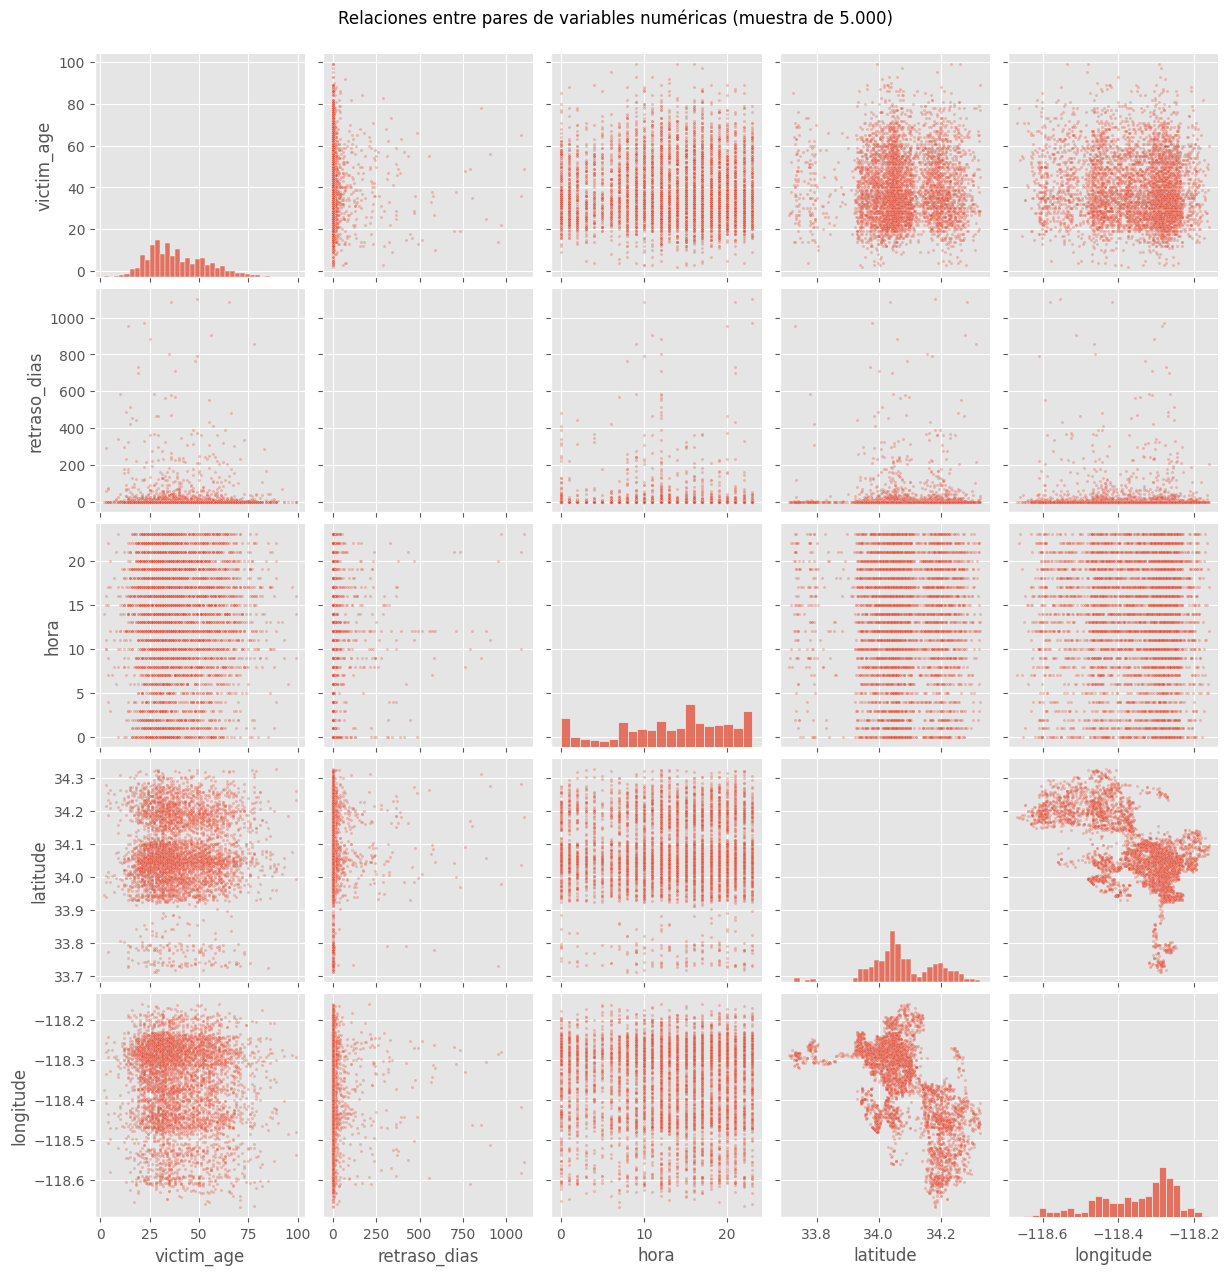

In [60]:
# Pairplot sobre una muestra de 5.000 casos (con todos, los puntos se tapan entre sí)
muestra_pp = base.sample(5000, random_state=42)
sns.pairplot(muestra_pp, vars=numericas, plot_kws={"s": 5, "alpha": 0.3})
plt.suptitle("Relaciones entre pares de variables numéricas (muestra de 5.000)", y=1.02)
plt.show()

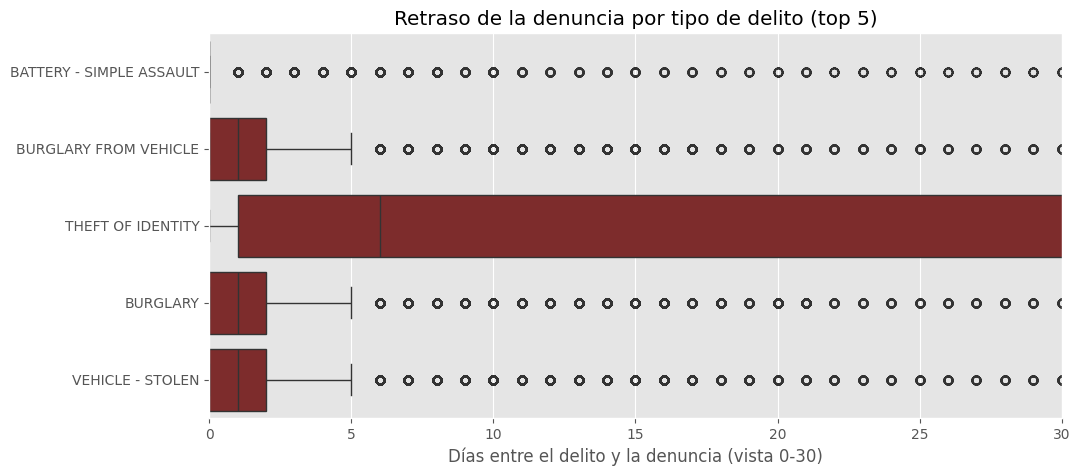

,retraso_dias
crime_description,
BATTERY - SIMPLE ASSAULT,0.0
BURGLARY,1.0
BURGLARY FROM VEHICLE,1.0
THEFT OF IDENTITY,6.0
VEHICLE - STOLEN,1.0


In [61]:
# Top 5 delitos para comparar grupos
top5 = df["crime_description"].value_counts().head(5).index
df_top5 = df[df["crime_description"].isin(top5)]
df_top5["crime_description"] = df_top5["crime_description"].astype("str")

# Boxplot: retraso de la denuncia por tipo de delito (eje recortado a 0-30 días para leerlo)
plt.figure(figsize=(11, 5))
sns.boxplot(data=df_top5, x="retraso_dias", y="crime_description", color="#8B1E1E")
plt.xlim(0, 30)
plt.title("Retraso de la denuncia por tipo de delito (top 5)")
plt.xlabel("Días entre el delito y la denuncia (vista 0-30)")
plt.ylabel("")
plt.show()
df_top5.groupby("crime_description")["retraso_dias"].median()

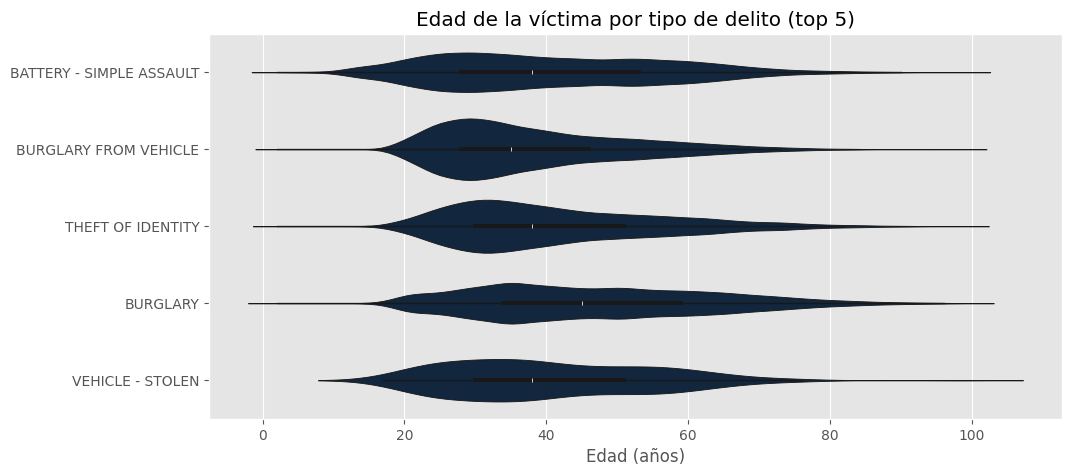

,victim_age
crime_description,
BATTERY - SIMPLE ASSAULT,38.0
BURGLARY,45.0
BURGLARY FROM VEHICLE,35.0
THEFT OF IDENTITY,38.0
VEHICLE - STOLEN,38.0


In [62]:
# Violin plot: edad de la víctima por tipo de delito (solo víctimas persona)
edad_top5 = df_top5[df_top5["victim_age"] > 0]
plt.figure(figsize=(11, 5))
sns.violinplot(data=edad_top5, x="victim_age", y="crime_description", color="#0b2545")
plt.title("Edad de la víctima por tipo de delito (top 5)")
plt.xlabel("Edad (años)")
plt.ylabel("")
plt.show()
edad_top5.groupby("crime_description")["victim_age"].median()

**Lectura de los grupos.** El robo de identidad se denuncia con una mediana de 6 días frente a 0 o 1 de los demás delitos, porque la víctima lo descubre después. El robo a vivienda tiene las víctimas de mayor edad (mediana 45 años) y la mayor dispersión; los otros cuatro delitos se centran en los 35-38 años. Las medianas y la forma de los violines muestran estas diferencias sin necesidad de pruebas estadísticas.

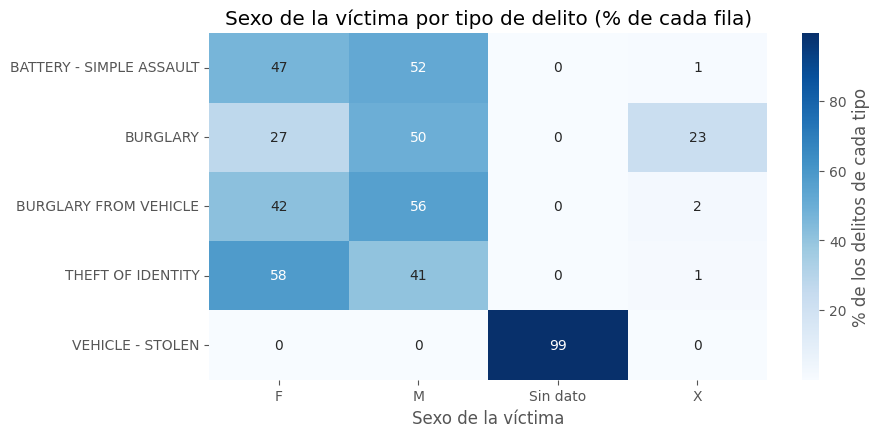

In [63]:
# Heatmap de tabla cruzada: tipo de delito x sexo de la víctima (% por fila)
tabla_sexo = pd.crosstab(df_top5["crime_description"], df_top5["victim_sex"].astype("str"), normalize="index") * 100
plt.figure(figsize=(9, 4.5))
sns.heatmap(tabla_sexo, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% de los delitos de cada tipo"})
plt.title("Sexo de la víctima por tipo de delito (% de cada fila)")
plt.xlabel("Sexo de la víctima")
plt.ylabel("")
plt.show()

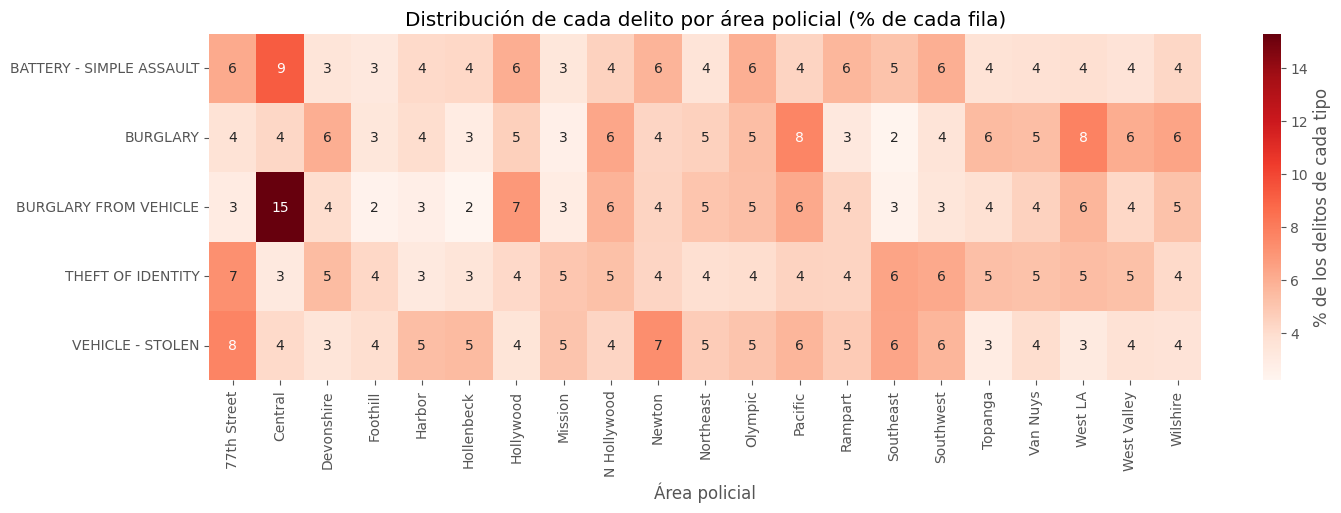

In [64]:
# Heatmap de tabla cruzada: tipo de delito x área policial (% por fila)
tabla_area = pd.crosstab(df_top5["crime_description"], df_top5["area_name"].astype("str"), normalize="index") * 100
plt.figure(figsize=(16, 4.5))
sns.heatmap(tabla_area, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% de los delitos de cada tipo"})
plt.title("Distribución de cada delito por área policial (% de cada fila)")
plt.xlabel("Área policial")
plt.ylabel("")
plt.show()

### Síntesis del Bloque 7
- **Numéricas:** sin relaciones entre edad, retraso, hora y ubicación; la correlación no es la herramienta para este dataset.
- **Por delito:** el robo de identidad se denuncia tarde (6 días) y afecta más a mujeres (58%); el robo desde vehículo afecta más a hombres (56%) y se concentra en Central (15%); el robo a vivienda tiene víctimas mayores (45 años) y un 23% de sexo "X", que corresponde a negocios; el robo de vehículo no registra víctima en el 99% de los casos, lo que explica las edades 0 del Bloque 2.
- **Implicación:** el perfil de la víctima y la zona cambian según el delito, por lo que la prevención debe diseñarse por tipo de delito y no de forma genérica.